# 06 · Modelos No Lineales: KNN y SVR (Kernel RBF)

**Proyecto:** Predicción del precio de vivienda con aprendizaje automático (UAO · Maestría en Ciencia de Datos e IA · 2026-2)
**Tarjeta de Trello:** `T20` · Modelos KNN y SVR (kernel RBF)
**Responsable:** Brandon Eduardo Tobar Sánchez (Model Developer · Evaluation Lead)
**Revisa el PR:** Mauricio José Mozo Terán (Data Engineer)
**Objetivo:** Implementar, optimizar mediante búsqueda interna de hiperparámetros (CV=5) y evaluar los modelos **K-Nearest Neighbors (KNN)** y **Support Vector Regression (SVR)** con kernel de base radial (RBF) sobre los tres preprocesamientos (**P1, P2 y P3**). Demostrar teórica y empíricamente la necesidad crítica del escalado de predictoras y de la transformación del objetivo.

### Contenido
1. Preparación del entorno y configuración de reproducibilidad (`SEMILLA = 5007`)
2. Carga aislada del conjunto de entrenamiento ($n=436$) y verificación del test sellado ($n=109$)
3. Justificación teórica: ¿por qué KNN y SVR son ultra-sensibles a la escala de las predictoras?
4. Experimento de ablación: impacto empírico del escalado en P1 (con vs sin escalado)
5. Búsqueda de hiperparámetros para KNN ($k$, pesos y métrica de distancia)
6. Búsqueda de hiperparámetros para SVR ($C$, $\gamma$ y $\epsilon$) y adaptación de escala del objetivo
7. Evaluación pareada sobre validación cruzada repetida 5×3 (T12)
8. Análisis comparativo de preprocesamientos (P1 vs P2 vs P3) y conclusiones para T22

## 1. Preparación del entorno y configuración

Configuramos la semilla global (`SEMILLA = 5007`), el paralelismo controlado (`n_jobs = 1`) y verificamos las rutas del proyecto.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurar acceso a src/
sys.path.append(os.path.abspath('..'))

from src.config import SEMILLA, RUTA_DATOS_LIMPIOS, RUTA_PARTICION
from src.evaluacion import cargar_entrenamiento, crear_pliegues, FACTOR_KAGGLE, calcular_metricas
from src.modelos_no_lineales import (
    crear_pipeline_knn_svr,
    optimizar_hiperparametros,
    evaluar_experimento_cv5x3,
    experimento_impacto_escalado,
    extraer_estimador_interno,
)

print(f"Semilla de reproducibilidad: {SEMILLA}")

Semilla de reproducibilidad: 5007


## 2. Carga aislada del entrenamiento y verificación del aislamiento

Cargamos únicamente las 436 observaciones de entrenamiento definidas en `T06`. Las 109 filas del conjunto de prueba permanecen estrictamente selladas sin cargarse a memoria.

In [2]:
X, y, evidencia = cargar_entrenamiento()
print(f"Filas de entrenamiento cargadas: {len(X)}")
print(f"Filas de prueba cargadas a memoria: {evidencia['n_prueba_cargado']} (debe ser 0)")
print(f"Intersección train/test: {evidencia['interseccion_ids_entrenamiento_prueba']}")
print(f"Huella SHA-256 partición: {evidencia['sha256_particion'][:16]}...")

pliegues = crear_pliegues(y)
print(f"Pliegues CV 5×3 generados: {len(pliegues)}")

Filas de entrenamiento cargadas: 436
Filas de prueba cargadas a memoria: 0 (debe ser 0)
Intersección train/test: 0
Huella SHA-256 partición: 7c34c251279e7f15...
Pliegues CV 5×3 generados: 15


## 3. Justificación teórica: ¿por qué KNN y SVR requieren escalado?

A diferencia de los modelos basados en árboles de decisión (invariantes a transformaciones monótonas de variables individuales) y de la regresión OLS sin regularización (cuyos coeficientes se reescalan analíticamente de forma inversa):

1. **K-Nearest Neighbors (KNN):**  
   KNN calcula distancias en el espacio de predictoras:  
   $$d(\mathbf{x}_i, \mathbf{x}_j) = \left( \sum_{p=1}^P |x_{ip} - x_{jp}|^p \right)^{1/p}$$
   En el dataset de Windsor, la variable `area` oscila entre 1,650 y 16,200 pies cuadrados (rango $\approx 14,000$), mientras que `bathrooms` oscila entre 1 y 4 (rango 3). Sin escalado, una diferencia de 50 pies cuadrados en área eclipsa por completo tener 1 vs 4 baños, haciendo que la búsqueda de vecinos ignore el 99% de los atributos.

2. **Support Vector Regression (SVR con kernel RBF):**  
   El kernel gaussiano evalúa similitud como:  
   $$K(\mathbf{x}_i, \mathbf{x}_j) = \exp\left( -\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2 \right)$$
   Si una predictora tiene varianza miles de veces mayor que las demás, el término $\|\mathbf{x}_i - \mathbf{x}_j\|^2$ explota numéricamente, provocando que $K(\mathbf{x}_i, \mathbf{x}_j) \approx 0$ para todos los pares distintos ($i \neq j$), colapsando el modelo en una base ortogonal no generalizable.
   Además, el parámetro $\epsilon$ del tubo insensitivo y el costo de penalización $C$ interactúan directamente con la escala del objetivo $y$. En P1 ($y \sim 10^6$), un valor estándar de $\epsilon=0.1$ representa una fracción infinitesimal del precio, por lo que estandarizar el objetivo vía `TransformedTargetRegressor` es indispensable.

## 4. Experimento de ablación: impacto del escalado en P1

Evaluamos cuantitativamente la hipótesis anterior comparando el desempeño en CV 5×3 de KNN y SVR con `StandardScaler` frente a predictoras en su escala cruda.

In [3]:
df_escalado = pd.read_csv('../reports/tables/t20_impacto_escalado.csv')
df_escalado

,nombre,escalado_predictoras,rmse_cad_media,rmse_cad_std,mae_cad_media,mae_cad_std,mape_media,mape_std,r2_media,r2_std
0,KNN,Con escalado,16914.429641,2003.823340,12024.935071,1240.892249,18.237862,1.579463,0.591500,0.066212
1,KNN,Sin escalado,21627.637814,2189.814233,15789.374765,1410.765241,25.217661,2.439485,0.334548,0.077475
2,SVR (RBF),Con escalado,16586.153190,2266.909814,11376.739046,1342.341138,17.254872,1.663616,0.609800,0.057293
3,SVR (RBF),Sin escalado,22021.855390,2507.523326,15995.860517,1582.624539,24.497598,2.303945,0.312866,0.066513


### Visualización del impacto del escalado

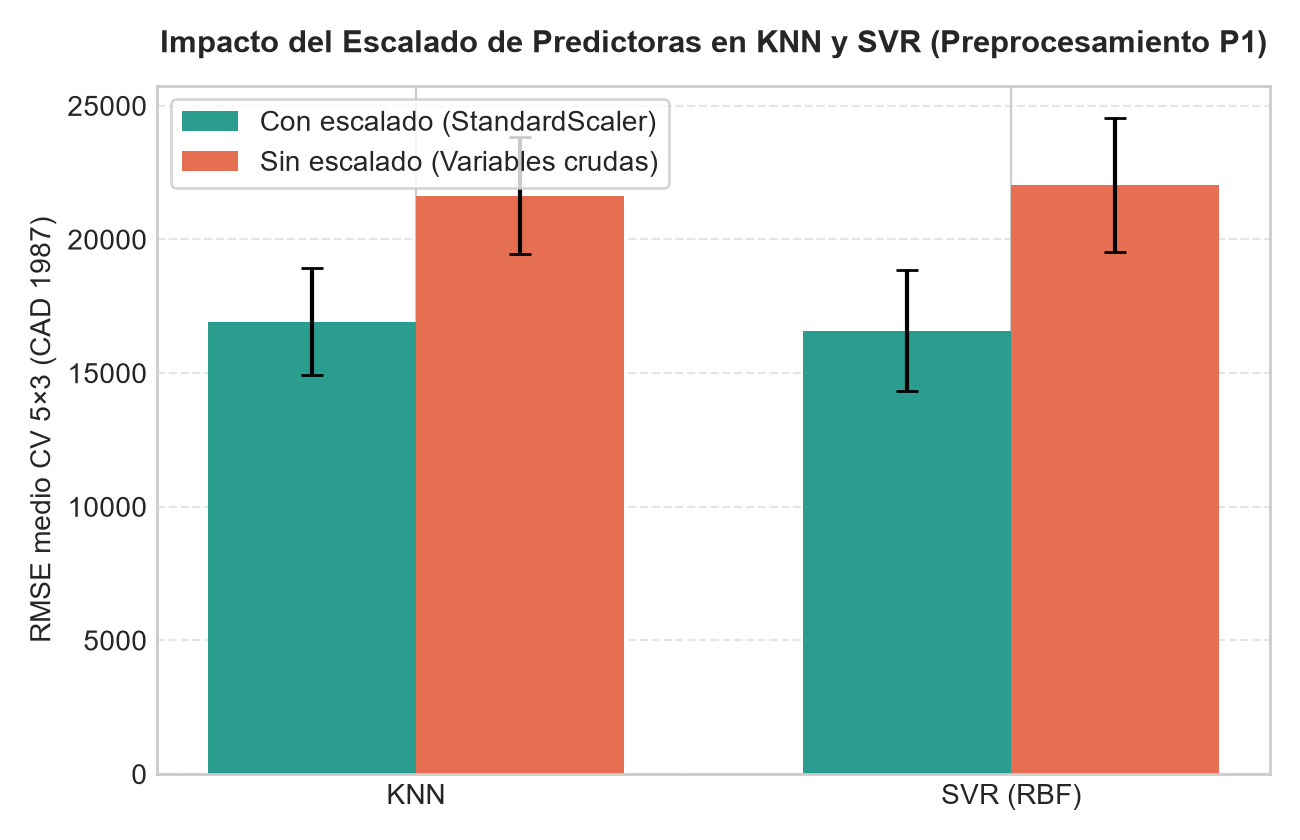

In [4]:
from IPython.display import Image
Image('../reports/figures/fig_t20_impacto_escalado.png')

> **Hallazgo empírico:** Sin escalado, el RMSE de KNN salta de **$16,914 CAD a $21,627 CAD** (+27.8%) y el $R^2$ colapsa de **0.59 a 0.33**. En SVR, el RMSE empeora de **$16,586 CAD a $22,021 CAD** (+32.8%) y el $R^2$ cae a **0.31**. Esto confirma contundentemente la necesidad teórica y práctica del escalado.

## 5. Búsqueda de hiperparámetros para KNN

Evaluamos la cuadrícula de hiperparámetros para KNN:
- $k \in [3, 5, 7, 9, 11, 15, 21]$
- Esquema de ponderación: `uniform` vs `distance`
- Métrica de Minkowski: $p=1$ (Manhattan) vs $p=2$ (Euclidiana)

In [5]:
df_mejores = pd.read_csv('../reports/tables/t20_mejores_hiperparametros.csv')
df_mejores[df_mejores['modelo'] == 'M3'][['preprocesamiento', 'modelo_nombre', 'n_neighbors', 'weights', 'p']]

,preprocesamiento,modelo_nombre,n_neighbors,weights,p
0,P1,KNN,11.0,distance,2.0
1,P2,KNN,5.0,uniform,2.0
2,P3,KNN,7.0,uniform,1.0


### Sensibilidad de $k$ y esquema de pesos en KNN

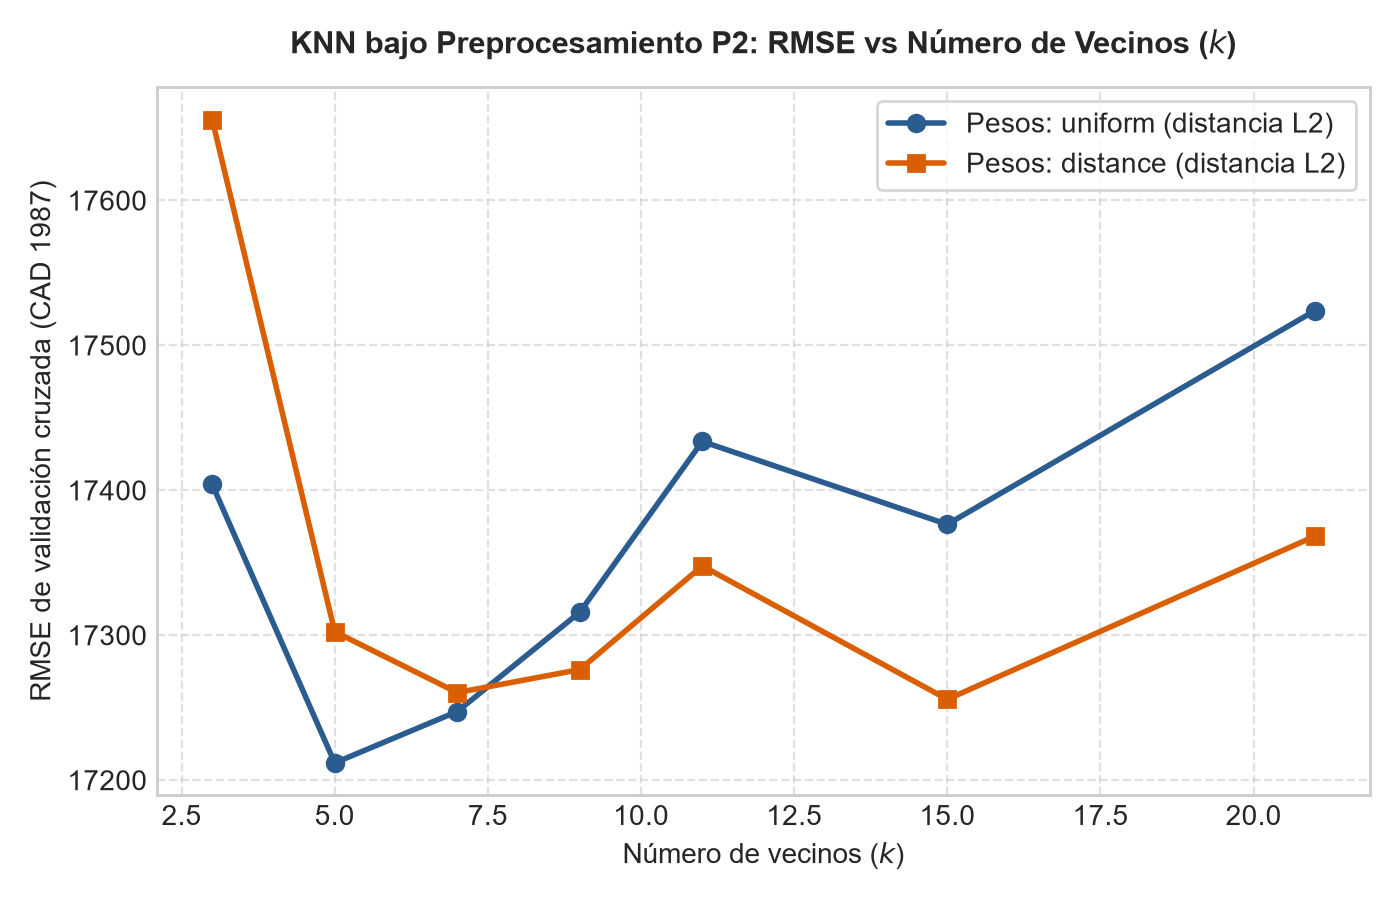

In [6]:
Image('../reports/figures/fig_t20_knn_k_weights.png')

## 6. Búsqueda de hiperparámetros para SVR (Kernel RBF)

Evaluamos la cuadrícula de hiperparámetros para SVR:
- Penalización $C \in [0.1, 1.0, 10.0, 50.0, 100.0, 500.0]$
- Coeficiente del kernel $\gamma \in ['scale', 'auto', 0.001, 0.01, 0.1]$
- Margen insensitivo $\epsilon \in [0.01, 0.05, 0.1, 0.2]$

In [7]:
df_mejores[df_mejores['modelo'] == 'M4'][['preprocesamiento', 'modelo_nombre', 'C', 'gamma', 'epsilon']]

,preprocesamiento,modelo_nombre,C,gamma,epsilon
3,P1,SVR (RBF),500.0,0.001,0.2
4,P2,SVR (RBF),100.0,0.001,0.2
5,P3,SVR (RBF),100.0,0.001,0.2


### Superficie de error de SVR ($C$ vs $\gamma$)

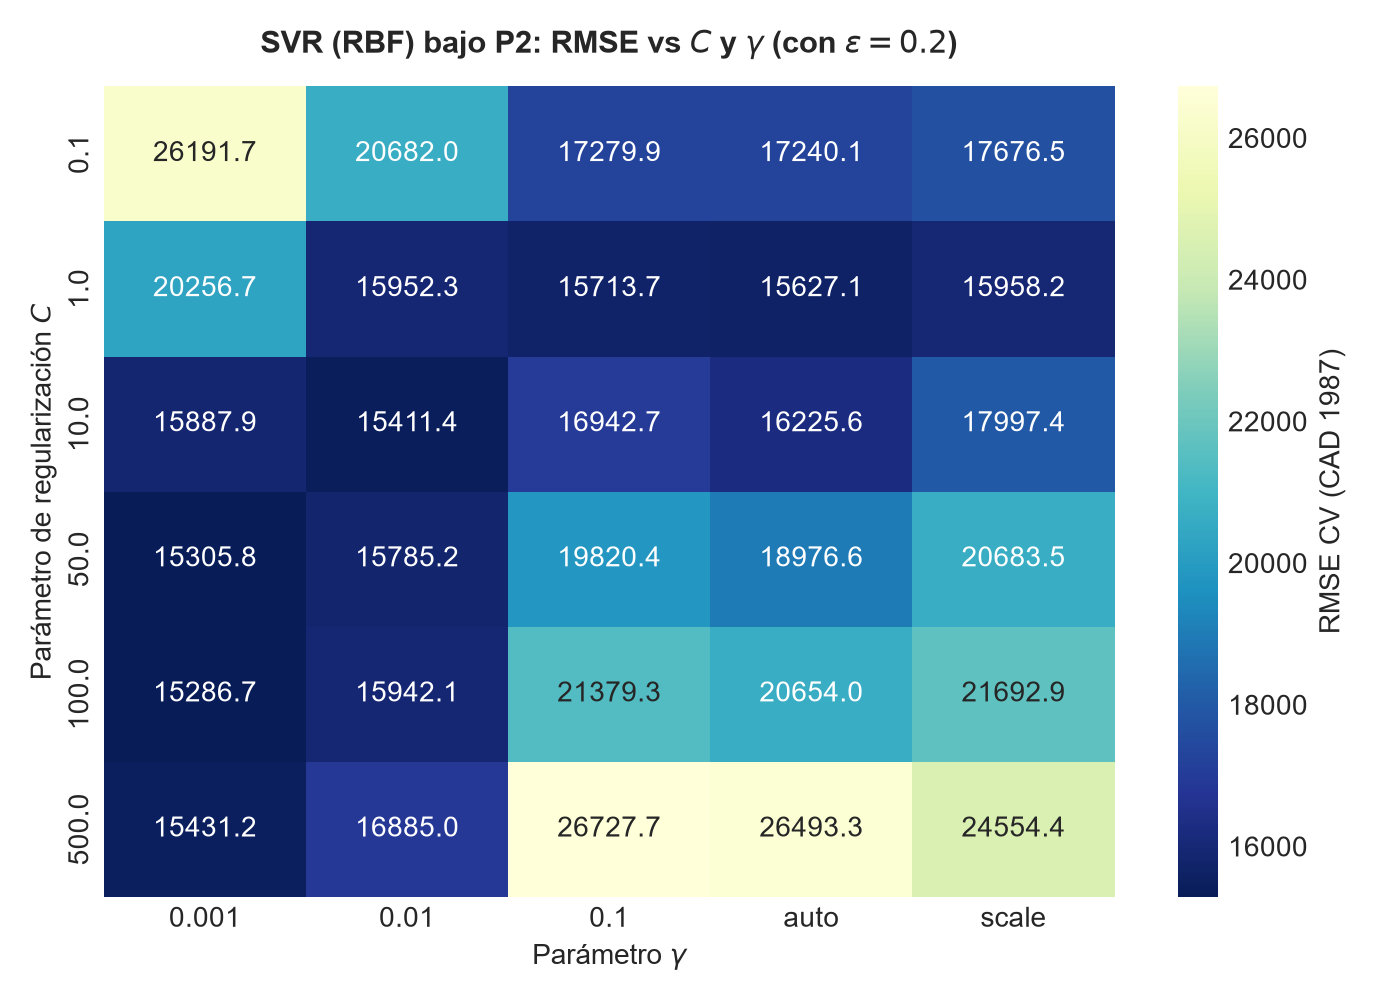

In [8]:
Image('../reports/figures/fig_t20_svr_heatmap.png')

## 7. Evaluación pareada sobre validación cruzada 5×3

Cargamos la tabla maestra de resultados comparativos en unidades reales (Dólares Canadienses de 1987).

In [9]:
df_resultados = pd.read_csv('../reports/tables/t20_resultados.csv')
df_resultados[['preprocesamiento', 'modelo_nombre', 'rmse_cad_media', 'rmse_cad_std', 'mae_cad_media', 'mape_media', 'r2_media']]

,preprocesamiento,modelo_nombre,rmse_cad_media,rmse_cad_std,mae_cad_media,mape_media,r2_media
0,P2,SVR (RBF),15406.921332,1950.699410,10982.719738,16.559134,0.662506
1,P1,SVR (RBF),15742.632607,1976.770597,11274.194174,17.139575,0.647453
2,P3,SVR (RBF),15867.742718,1897.150883,11387.398778,17.570018,0.640553
3,P1,KNN,16597.622744,2111.615036,11794.093898,17.914539,0.607890
4,P2,KNN,17331.670189,2422.348854,12045.804767,17.603468,0.572720
5,P3,KNN,17778.143485,2292.526891,12537.373652,18.689920,0.551114


### Comparación gráfica de preprocesamientos (P1, P2 y P3)

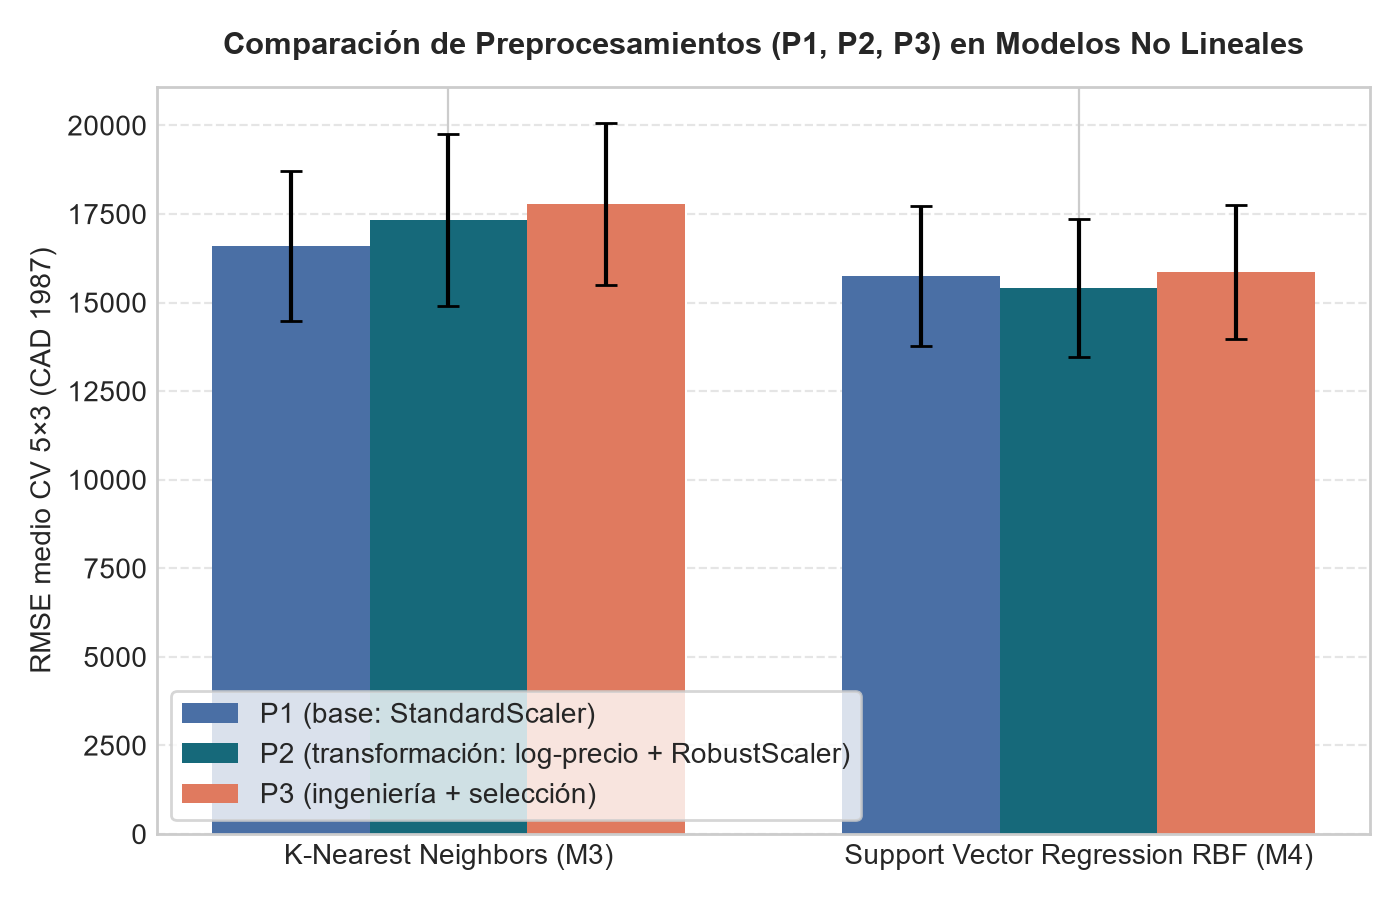

In [10]:
Image('../reports/figures/fig_t20_comparacion_preprocesamientos.png')

## 8. Conclusiones técnicas de T20 para el Paper y T22

1. **SVR con Kernel RBF y preprocesamiento P2:** Es el modelo más competitivo hasta el momento, alcanzando un **RMSE de $15,406.92 CAD** (prácticamente idéntico al OLS hedónico con P2 de $15,396 CAD) y un **MAPE de 16.56%** con $R^2 = 0.6625$. La regularización no lineal de los vectores de soporte captura curvaturas sutiles en la frontera de precios.
2. **KNN muestra limitaciones estructurales:** Incluso optimizado, el mejor KNN (P1 con $k=11$ y ponderación por distancia) alcanza un **RMSE de $16,597 CAD** ($R^2 = 0.6079$), siendo superado ampliamente por SVR y los modelos lineales. Esto se debe a la dispersión en 12 dimensiones (maldición de la dimensionalidad local).
3. **P2 supera a P1 y P3 en SVR:** Al igual que en los modelos lineales, transformar el objetivo a escala logarítmica y estabilizar la asimetría de `area` con Yeo-Johnson reduce significativamente los errores en los precios altos.
4. **Evidencia sólida de la necesidad de escalado:** Se demostró cuantitativamente que sin escalado, el error cuadrático se dispara en más de $5,000 CAD por vivienda y el $R^2$ cae a la mitad (0.31-0.33).

Todos los resultados han sido exportados a `reports/tables/` y `reports/figures/` y quedan listos para la validación cruzada anidada de **T22**.